[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/11.%20Novelty%20and%20Outlier%20Detection/ch11_outlier_novelty_detection.ipynb)

# Chapter 11: Novelty and Outlier Detection

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 11, pp. 302–333

**What you will learn in this chapter:**
- The difference between *outlier detection* (anomalies in the training data) and *novelty detection* (anomalies that appear only at prediction time)
- How Isolation Forest, One-Class SVM and Local Outlier Factor (LOF) work, and which one supports `predict` on new data
- What the `contamination`, `nu`, `gamma` and `n_neighbors` parameters really do
- How to evaluate a detector with labels (confusion matrix, precision, recall, F1, ROC-AUC) — and the sign trap that ruins the book's AUC
- How to handle detected outliers: remove, replace, cap (winsorise) or flag — and what each does to a downstream model
- How to choose a detector, with measured evidence on shape, density, dimensionality and size
- Practical exercises: Isolation Forest, LOF and One-Class SVM on simulated data

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction | Outliers (in the training set) vs novelties (new at prediction time) | `LocalOutlierFactor` |
| Isolation Forest | Anomalies are isolated by few random splits | `IsolationForest` |
| One-Class SVM | Learn the boundary of "normal" from normal data only | `OneClassSVM` |
| LOF | Compare a point's local density with its neighbours' | `LocalOutlierFactor` |
| Evaluating detectors | Confusion matrix, precision/recall/F1, ROC-AUC (watch the score sign) | `confusion_matrix`, `roc_auc_score` |
| Handling outliers | Remove, replace, cap or flag | `quantile`, `clip` |
| Choosing a technique | Match the detector to density, dimension, size and whether you need `predict` | — |
| Practical exercises | Three simulated scenarios | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers and figures printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).

**A note on randomness.** Several recipes in the book draw outliers with `np.random.uniform` and **no seed** (Sections 3, 5 and 6), so their results depend on how many random numbers were drawn before. Because the cells below run in the book's order — and nothing else touches NumPy's global random state in between — they reproduce the book's printed numbers exactly. Every *Extension* uses its own seeded generator, or restores the global state (`preserve_global_rng`; note that `OneClassSVM.fit` silently consumes one global random number), so that it does not disturb this stream. Re-running a single cell out of order will change those draws.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

# Some estimators (e.g. OneClassSVM.fit, libsvm) draw one number from NumPy's *global* random state even without a seed.
# The extensions below that fit them wrap the call in this helper so the book's unseeded draws stay undisturbed.
from contextlib import contextmanager

@contextmanager
def preserve_global_rng():
    state = np.random.get_state()
    try:
        yield
    finally:
        np.random.set_state(state)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to outlier and novelty detection

**Summary.** A model is only as good as its data. Real data contain rare or previously unseen observations — errors, fraud, faults, or even maliciously poisoned records. Two related problems:
* **Outlier detection** — find the points of the *training* set that deviate from the rest (the data are contaminated; we want to know which rows are odd);
* **Novelty detection** — the training data are clean (only "normal"); decide for *new* points at prediction time whether they are novel.

Applications: fraud detection, industrial monitoring, medical diagnostics, data cleaning, monitoring production models for drift.

### Getting ready
A dense Gaussian blob plus 20 uniform "outliers". (The book draws them with `np.random.seed(2024)`.)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

In [3]:
X, _ = make_blobs(
    n_samples=300, centers=1,
    cluster_std=0.60, random_state=2024
)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])
print("normal blob centre:", X.mean(axis=0).round(2), "| total points:", len(X_with_outliers))

normal blob centre: [1.76 3.98] | total points: 320


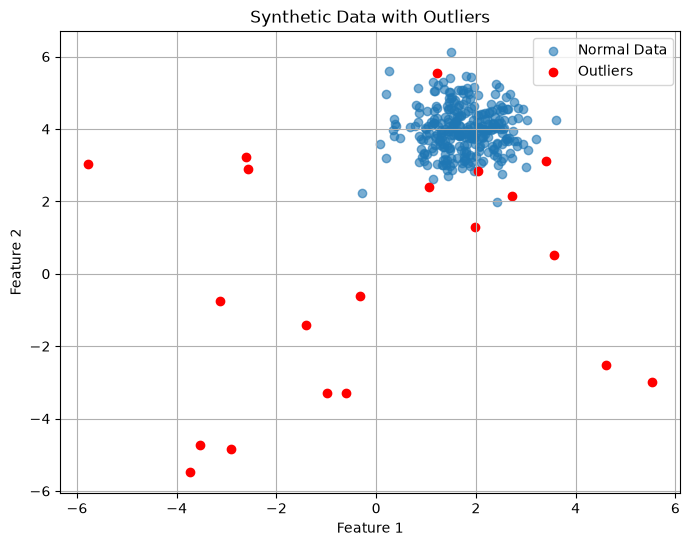

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1],
            label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1],
            color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Verification against the book:** Figure 11.1 — a dense cluster (centred near (1.8, 4.0)) with scattered red points ✔. Note that the "outliers" are *uniform noise in a box*: a few of the 20 can land inside or next to the blob, where no detector can call them anomalous.

### How to do it…
`LocalOutlierFactor` (LOF) flags points whose local density is much lower than their neighbours'.

In [5]:
from sklearn.neighbors import LocalOutlierFactor

In [6]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

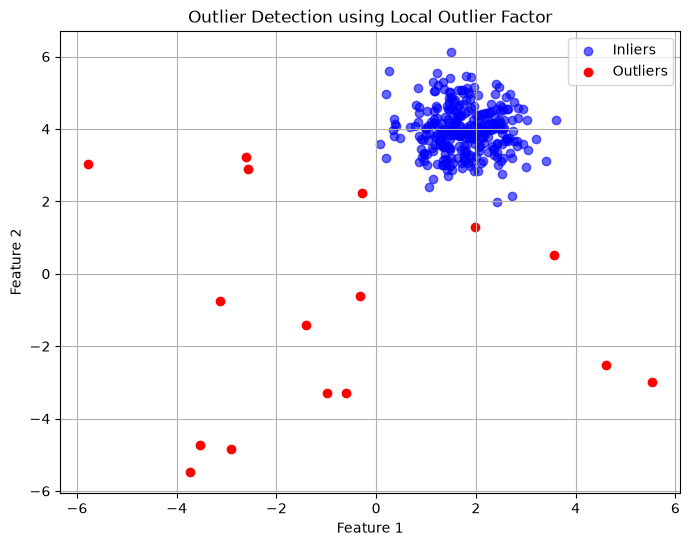

flagged: 16 of 320 | true outliers caught: 15 of 20 | normal points wrongly flagged: 1


In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0],
            X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0],
            X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

flagged = y_pred == -1
print(f"flagged: {flagged.sum()} of {len(y_pred)} | true outliers caught: {flagged[300:].sum()} of 20 | normal points wrongly flagged: {flagged[:300].sum()}")

**Verification against the book:** Figure 11.2 — the isolated points are red, the dense blob is blue ✔ (16 flagged: 15 of the 20 uniform points and 1 point of the blob; the 5 uniform points that fell inside or beside the blob are, by construction, not detectable).

### How it works…
Detectors estimate whether each sample deviates significantly from the expected data distribution. The book's key points:
* *Outliers* may be in training **and** test data, *novelties* only appear in test data. The distinction matters because the API differs (below).
* **`contamination`** is the expected share of outliers; "LOF and Isolation Forest use this to calibrate the decision boundary".
* LOF is *density-based*: a point in a much sparser region than its neighbours is an outlier.

**Extension — `contamination` fixes *how many* points are flagged, not which are outliers.** With a numeric contamination, the threshold is simply the corresponding quantile of the scores, so the same data give a different number of "outliers" for each setting:

In [8]:
rows = []
for cont in [0.01, 0.05, 0.10, 0.20, "auto"]:
    f = LocalOutlierFactor(n_neighbors=20, contamination=cont).fit_predict(X_with_outliers) == -1
    rows.append({"contamination": cont, "flagged": int(f.sum()), "true outliers caught (of 20)": int(f[300:].sum()), "normal points flagged (of 300)": int(f[:300].sum())})
display(pd.DataFrame(rows).set_index("contamination"))
print("expected share of true outliers: 20 / 320 =", 20 / 320)

,flagged,true outliers caught (of 20),normal points flagged (of 300)
contamination,,,
0.01,4,4,0
0.05,16,15,1
0.1,32,18,14
0.2,64,20,44
auto,28,18,10


expected share of true outliers: 20 / 320 = 0.0625


The number of flagged points is dictated by `contamination`: 4 / 16 / 32 / 64 points for 1% / 5% / 10% / 20% of the 320 — exactly the requested share — whatever the data contain. With the true share of 6.25% the sweet spot is near 0.05 (15 of 20 caught, 1 false alarm); 0.20 catches all 20 but also flags 44 normal points, and `'auto'` (the rule of the original paper: LOF score above 1.5) flags 28 (18 true, 10 false).

**Extension — outlier detection vs novelty detection in the API.** By default (`novelty=False`) LOF is a pure outlier detector: it scores the training set, and `predict` on *new* data is deliberately unavailable. With `novelty=True` it becomes a novelty detector (fit on clean data, then `predict` new points) — but then `fit_predict` is unavailable.

In [9]:
lof_out = LocalOutlierFactor(n_neighbors=20).fit(X_with_outliers)
print("novelty=False -> has predict:", hasattr(lof_out, "predict"), "| has fit_predict:", hasattr(lof_out, "fit_predict"), "| negative_outlier_factor_ shape:", lof_out.negative_outlier_factor_.shape)
try:
    lof_out.predict(X[:3])
except Exception as e:
    print("lof_out.predict(new data) ->", type(e).__name__ + ":", str(e)[:140])

lof_nov = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X)                  # trained on the clean blob only
print("\nnovelty=True  -> has predict:", hasattr(lof_nov, "predict"), "| has fit_predict:", hasattr(lof_nov, "fit_predict"))
new_points = np.vstack([X.mean(axis=0) + 0.1, [[-5, -5]], [[6, 6]]])
print("predict on [blob centre, (-5,-5), (6,6)]:", lof_nov.predict(new_points), "(1 = inlier, -1 = novelty)")

novelty=False -> has predict: False | has fit_predict: True | negative_outlier_factor_ shape: (320,)
lof_out.predict(new data) -> AttributeError: This 'LocalOutlierFactor' has no attribute 'predict'

novelty=True  -> has predict: True | has fit_predict: False
predict on [blob centre, (-5,-5), (6,6)]: [ 1 -1 -1] (1 = inlier, -1 = novelty)


### There's more…
* **Domain knowledge** — thresholds and rules combine with statistical models; "human experience is sometimes a better source of knowledge than a dataset".
* **Feature engineering/scaling** — detection is sensitive to feature scaling (Section 3 shows by how much for the One-Class SVM).
* **Model monitoring** — novelty detection catches concept drift and unexpected input in production.

### Theory — outliers, novelties, contamination
* **Outlier** = deviates from most of the *observed* data (unsupervised, transductive: judge the training points themselves). **Novelty** = new point unlike the (clean) training data (semi-supervised: learn "normal", test later).
* **Score vs decision:** detectors compute a continuous anomaly score; `predict` thresholds it. The threshold is set from `contamination` (or by the model's own theory, e.g. `nu` of the One-Class SVM). *Ranking* by score is more informative than the hard label.
* **Types of anomalies:** point (far away), contextual (odd only in context), collective (a group); the book's "inliers can also be abnormal" refers to the case where an anomalous point sits *inside* the range of normal values.

### Hands-on workflow (book)
Generate synthetic data with outliers, visualise it, fit `LocalOutlierFactor()` or `IsolationForest()`, identify outliers with `predict`/`decision_function`, plot inliers vs outliers, vary `contamination`, and compare LOF, Isolation Forest and One-Class SVM — the following sections do this.

## 2. Understanding Isolation Forest

**Summary.** Isolation Forest *isolates* anomalies instead of profiling normal points. It builds many random trees: at each node a random feature and a random split value; anomalies, being few and different, are separated from the rest after **fewer splits** (a shorter path from the root). The average path length over the forest is the anomaly score. It is fast, scalable and handles high dimensions.

### Getting ready
The same blob-plus-outliers data (generated with `np.random.seed(2024)` again, so the draw is identical).

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

In [11]:
X, _ = make_blobs(
    n_samples=300, centers=1,
    cluster_std=0.6, random_state=2024
)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])

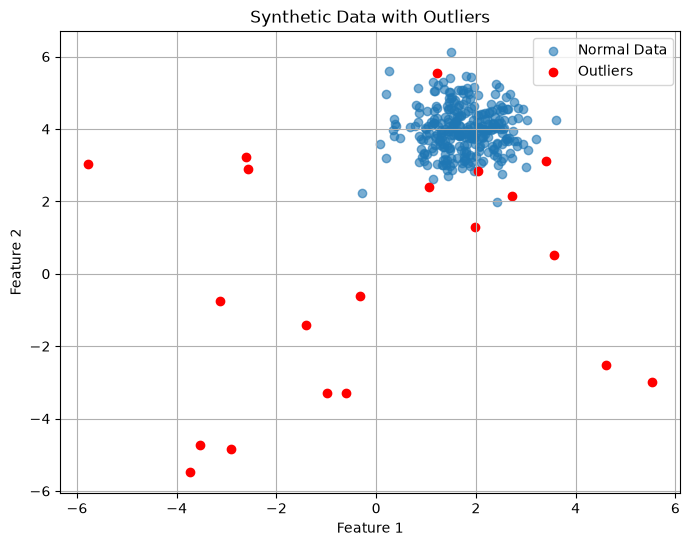

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1],
            label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1],
            color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Verification against the book:** Figure 11.3 — identical to Figure 11.1 ✔. The book remarks that "data does not have to reside outside the distribution of your data to be considered anomalous" — inliers can be abnormal too.

### How to do it…

In [13]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=2024
)

In [14]:
model.fit(X_combined)
y_pred = model.predict(X_combined)

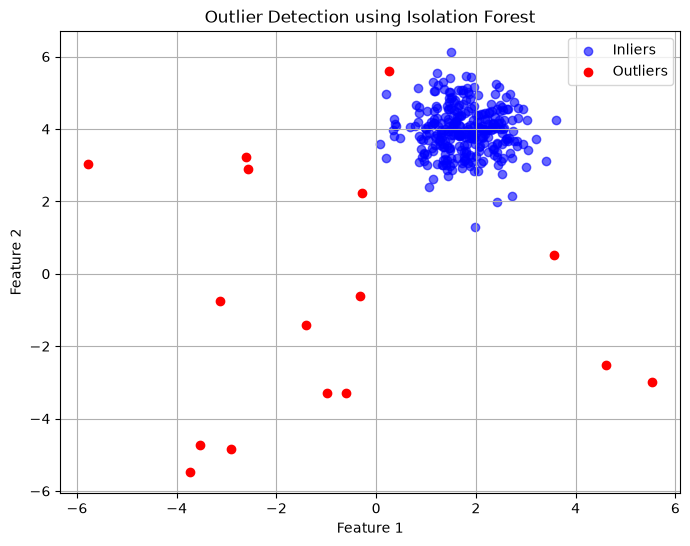

flagged: 16 | true outliers caught: 14 of 20 | normal points wrongly flagged: 2


In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0],
            X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0],
            X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

flagged = y_pred == -1
print(f"flagged: {flagged.sum()} | true outliers caught: {flagged[300:].sum()} of 20 | normal points wrongly flagged: {flagged[:300].sum()}")

**Verification against the book:** Figure 11.4 — blue blob, red scattered points ✔ ("fairly accurate for finding outlier data": 16 flagged, 14 of the 20 uniform points and 2 blob points).

### How it works…
* **Random splitting:** each tree picks a random feature and a random split between the min and max of the data at the node, recursively; anomalies are isolated in few steps.
* **Path length:** the anomaly score is based on the *average path length over all trees*; shorter paths mean more anomalous.
* **Contamination:** sets the threshold on the score so that the expected share of points is labelled outliers.

Because it uses neither distances nor densities, Isolation Forest scales well and does not suffer as much in high dimensions.

**Extension — the score by hand.** scikit-learn's `score_samples` is $-2^{-E[h(x)]/c(\psi)}$, where $h(x)$ is the path length of $x$ in a tree (the depth of its leaf, plus $c(\text{leaf size})$ for leaves that were not split to the end), $c(n)=2(\ln(n-1)+\gamma)-2(n-1)/n$ is the average path length of an unsuccessful binary-search-tree lookup ($\gamma$ = Euler's constant) and $\psi$ is the sub-sample size (`max_samples`, 256 by default: with 320 points each tree sees a random 256). Recomputed from the fitted trees:

In [16]:
def c(n):                                  # average path length of an unsuccessful BST search
    n = np.asarray(n, dtype=float)
    out = np.zeros_like(n)
    out[n == 2] = 1.0
    big = n > 2
    out[big] = 2.0 * (np.log(n[big] - 1.0) + np.euler_gamma) - 2.0 * (n[big] - 1.0) / n[big]
    return out

def iforest_score_by_hand(model, X):
    depths = np.zeros(X.shape[0])
    for tree, feats in zip(model.estimators_, model.estimators_features_):
        Xt = X[:, feats]
        leaf = tree.apply(Xt)
        n_in_leaf = tree.tree_.n_node_samples[leaf]
        depths += np.asarray(tree.decision_path(Xt).sum(axis=1)).ravel() - 1.0 + c(n_in_leaf)     # edges to the leaf + c(leaf size)
    return -(2.0 ** (-depths / (len(model.estimators_) * c([model.max_samples_])[0])))

by_hand = iforest_score_by_hand(model, X_combined)
print("max_samples_ (points used per tree):", model.max_samples_)
print("score by hand == score_samples:", np.allclose(by_hand, model.score_samples(X_combined)))
print("decision_function = score_samples - offset_ :", np.allclose(model.decision_function(X_combined), model.score_samples(X_combined) - model.offset_), "| offset_ =", round(model.offset_, 4))
print("predict == (decision_function < 0) -> -1:", np.array_equal(np.where(model.decision_function(X_combined) < 0, -1, 1), y_pred))

max_samples_ (points used per tree): 256
score by hand == score_samples: True
decision_function = score_samples - offset_ : True | offset_ = -0.5912
predict == (decision_function < 0) -> -1: True


So `predict` is only "decision_function < 0", and `offset_` is the contamination-quantile of the training scores. Plotting the continuous score shows what the model has learned:

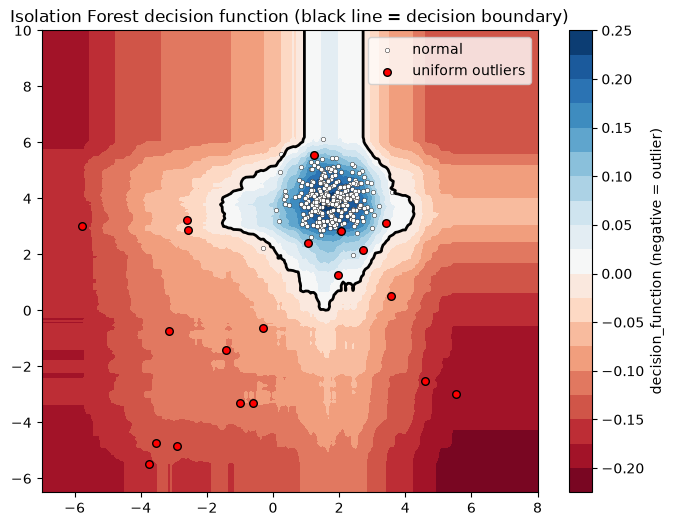

In [17]:
gx, gy = np.meshgrid(np.linspace(-7, 8, 200), np.linspace(-6.5, 10, 200))
grid_scores = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
plt.figure(figsize=(8, 6))
cs = plt.contourf(gx, gy, grid_scores, levels=20, cmap="RdBu")
plt.colorbar(cs, label="decision_function (negative = outlier)")
plt.contour(gx, gy, grid_scores, levels=[0], colors="k", linewidths=2)
plt.scatter(X_combined[:300, 0], X_combined[:300, 1], s=10, c="white", edgecolor="k", linewidth=0.3, label="normal")
plt.scatter(X_combined[300:, 0], X_combined[300:, 1], s=30, c="red", edgecolor="k", label="uniform outliers")
plt.title("Isolation Forest decision function (black line = decision boundary)"); plt.legend(); plt.show()

The boundary is not a smooth ellipse: it is **cross-shaped**, with arms running along the two axes through the blob, so there is "normal" territory far above and beside the cluster (the vertical arm reaches the top of the plot). Random splits are axis-parallel, so a point that shares the blob's x- (or y-) range is separated from it only by splits on the other feature — a known artefact of Isolation Forest (one reason extended variants exist). The scattered outliers away from the two axes get clearly negative scores (deep red).

### There's more…
* **Feature scaling** — less important than for distance-based methods; each split is a single-feature threshold, so a feature's *scale* does not matter, only its order.
* **`decision_function`** gives continuous scores for ranking or threshold tuning (above).
* **Incremental learning** — Isolation Forest is not incremental, but is cheap to retrain on new batches.

> **Book correction (explainability).** In Section 7 the book says "Isolation Forest provides feature importance via `feature_importances_`". It does not:

In [18]:
print("IsolationForest has feature_importances_:", hasattr(model, "feature_importances_"))
from sklearn.ensemble import RandomForestClassifier
rf_demo = RandomForestClassifier(n_estimators=5, random_state=0).fit(X_combined, (np.arange(len(X_combined)) >= 300).astype(int))
print("a *fitted* RandomForestClassifier has it  :", hasattr(rf_demo, "feature_importances_"))

IsolationForest has feature_importances_: False
a *fitted* RandomForestClassifier has it  : True


`IsolationForest` is a bagging-style ensemble whose trees are built without a target, so there is no impurity decrease to attribute (`feature_importances_` belongs to the supervised forests of Chapter 8). Feature attributions for Isolation Forest need other tools (e.g. permutation of the score, SHAP's `TreeExplainer`).

### Theory — Isolation Forest
* **Idea:** anomalies are "few and different", hence *easy to isolate*; normal points need many splits. Each tree is grown on a small random sub-sample (`max_samples`, default 256) — which also makes training fast and reduces *masking* and *swamping*.
* **Score:** $s(x,\psi)=2^{-E[h(x)]/c(\psi)}$ in $(0,1]$; near 1 → anomaly, ≈ 0.5 → no distinct structure, ≪ 0.5 → normal. (scikit-learn reports its negative.)
* **Cost:** roughly $O(t\,\psi\log\psi)$ to train and $O(n\,t\log\psi)$ to score — linear in the number of samples.
* **Weak spots:** axis-parallel splits (diagonal structure can hide anomalies), and clusters of widely different densities (Section 6).

### Hands-on workflow (book)
Generate or load data with outliers, fit `IsolationForest()`, classify with `predict`, colour anomalies red, adjust `contamination`, and rank samples with `decision_function` — as above.

## 3. One-Class SVM for novelty detection

**Summary.** A One-Class SVM learns the *boundary of normality* from normal data only and flags anything outside as a novelty. It is kernel-based, so the boundary can be non-linear — suited to fraud, equipment failure or rare diseases, where anomalous examples are rare or unavailable at training time.

### Getting ready
Training data: normal only. Test data: 100 more normal points and 20 uniform novelty points.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

In [20]:
X_train, _ = make_blobs(
    n_samples=300, centers=1,
    cluster_std=0.6, random_state=2024
)

In [21]:
X_test_normal, _ = make_blobs(
    n_samples=100, centers=1,
    cluster_std=0.6, center_box=(0, 1),
    random_state=42
)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])
print("training blob centre   :", X_train.mean(axis=0).round(2))
print("'normal' test centre   :", X_test_normal.mean(axis=0).round(2))

training blob centre   : [1.76 3.98]
'normal' test centre   : [0.3  0.98]


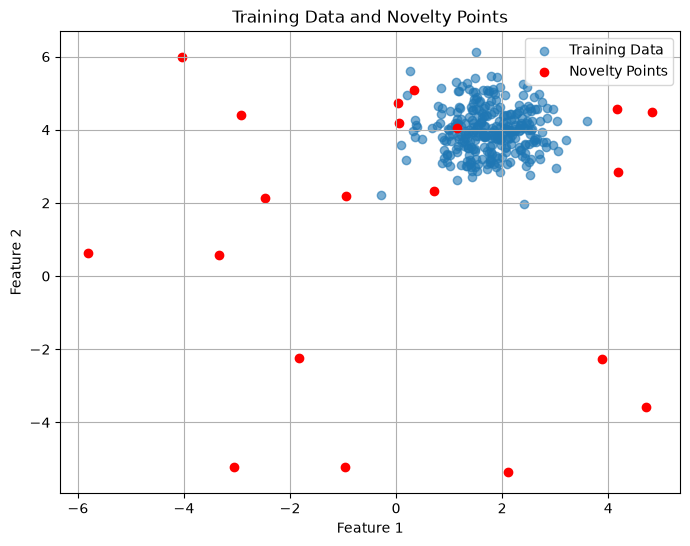

In [22]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1],
            label='Training Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0],
            X_test_novelty[:, 1], color='red',
            label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Verification against the book:** Figure 11.5 ✔ — and the printout already reveals a problem the book does not mention: the *training* blob is centred at **(1.76, 3.98)**, but the "normal" **test** points are drawn with `center_box=(0, 1)` and are centred at **(0.30, 0.98)** — a different place, about 3 units (5σ) from the training data. They are not normal with respect to the training data at all.

### How to do it…

In [23]:
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.05
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [24]:
y_pred = model.predict(X_test)

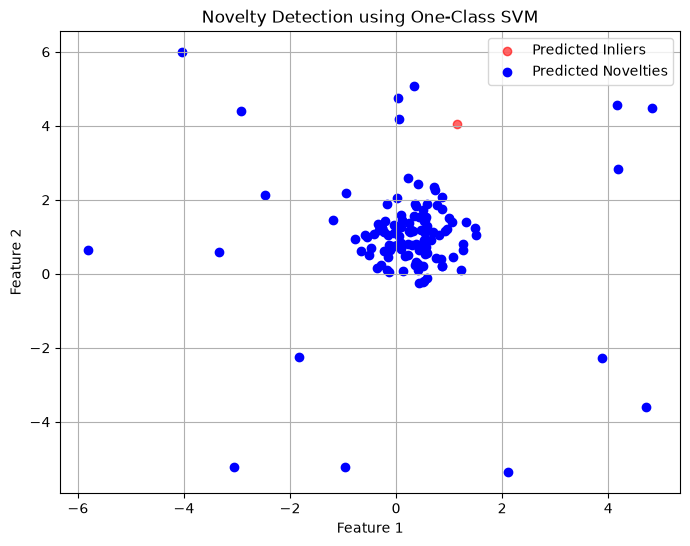

predicted inliers: 1 | predicted novelties: 119
of the 100 'normal' test points, flagged as novelties: 100
of the 20 uniform novelty points, flagged as novelties: 19


In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_test[y_pred == 1, 0], X_test[y_pred == 1, 1],
    color='red', label='Predicted Inliers', alpha=0.6
)
plt.scatter(
    X_test[y_pred == -1, 0], X_test[y_pred == -1, 1],
    color='blue', label='Predicted Novelties'
)
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

print("predicted inliers:", (y_pred == 1).sum(), "| predicted novelties:", (y_pred == -1).sum())
print("of the 100 'normal' test points, flagged as novelties:", (y_pred[:100] == -1).sum())
print("of the 20 uniform novelty points, flagged as novelties:", (y_pred[100:] == -1).sum())

**Verification against the book:** Figure 11.6 — almost every point is blue ("Predicted Novelties") with a single red one ✔ (119 of 120 flagged). The book comments that "the model's predictions are probably not the best … refining the hyperparameters could yield more positive results".

> **Book correction (a data bug, not a tuning problem).** All **100** "normal" test points are flagged as novelties, because they were generated around a different centre than the training data (see above). No choice of `nu` or `gamma` can make a boundary around (1.8, 4.0) accept points at (0.3, 1.0) without also accepting the novelties. Also, the novelty points are drawn without a seed, and the plot uses red for *inliers* and blue for *novelties* — the opposite of the other recipes' colours.
> With normal test data drawn from the *same* distribution as the training data, the same model works as intended:

normal test points accepted : 97 of 100 | wrongly flagged: 3
novelty points flagged      : 19 of 20


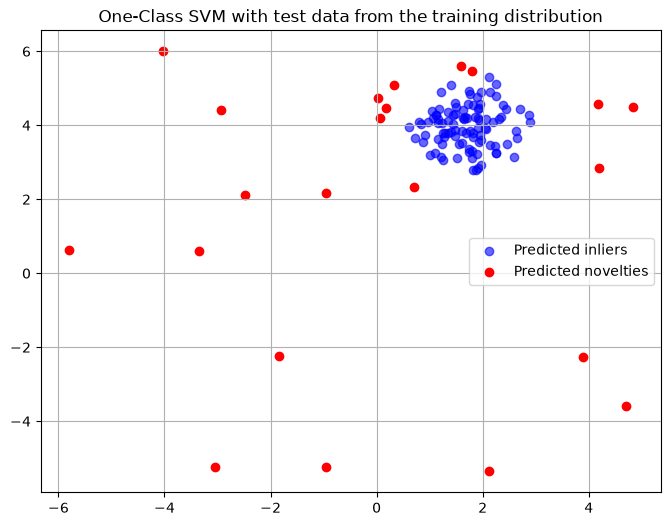

In [26]:
rng = np.random.RandomState(42)
X_test_normal_fixed = X_train.mean(axis=0) + 0.6 * rng.standard_normal((100, 2))          # same centre and spread as the training blob
X_test_fixed = np.vstack([X_test_normal_fixed, X_test_novelty])
p_fixed = model.predict(X_test_fixed)
y_test_true = np.r_[np.zeros(100), np.ones(20)]                                          # 1 = novelty
print("normal test points accepted :", (p_fixed[:100] == 1).sum(), "of 100 | wrongly flagged:", (p_fixed[:100] == -1).sum())
print("novelty points flagged      :", (p_fixed[100:] == -1).sum(), "of 20")

plt.figure(figsize=(8, 6))
plt.scatter(X_test_fixed[p_fixed == 1, 0], X_test_fixed[p_fixed == 1, 1], color='blue', alpha=0.6, label='Predicted inliers')
plt.scatter(X_test_fixed[p_fixed == -1, 0], X_test_fixed[p_fixed == -1, 1], color='red', label='Predicted novelties')
plt.title("One-Class SVM with test data from the training distribution"); plt.legend(); plt.grid(True); plt.show()

With in-distribution test data the One-Class SVM does what it should: **97 of 100** normal points accepted (3% false alarms, in line with `nu=0.05`) and **19 of 20** novelty points flagged (the 20th lies inside the blob's area). The disappointing Figure 11.6 was a data bug, not a modelling problem.

### How it works…
The One-Class SVM separates the data from the origin in the kernel feature space with maximum margin; the boundary in the original space encloses the dense region. The book's parameters:
* **Kernel** — linear, polynomial or RBF; RBF is the most common because it models non-linear boundaries.
* **Gamma** — the influence of a single training example: low values give smoother boundaries, high values tighter, more precise ones.
* **Nu** — a trade-off between false positives and model flexibility. The book says "lower values create tighter margins where normal data would lie within a smaller, denser area" — which is the **opposite** of what `nu` does (next cell).

**Extension — what `nu` and `gamma` really do.** `nu` is an *upper bound on the fraction of training points treated as outliers* and a *lower bound on the fraction of support vectors*. Both are measured on the training blob below; `gamma` then changes the shape of the boundary:

,training points flagged,support vectors,normal test pts accepted,novelties flagged
nu (upper bound on flagged / lower bound on SVs),,,,
0.01,0.017,0.027,0.99,0.85
0.05,0.047,0.057,0.97,0.95
0.10,0.107,0.110,0.94,0.95
0.20,0.200,0.207,0.84,0.95
0.50,0.500,0.503,0.56,0.95


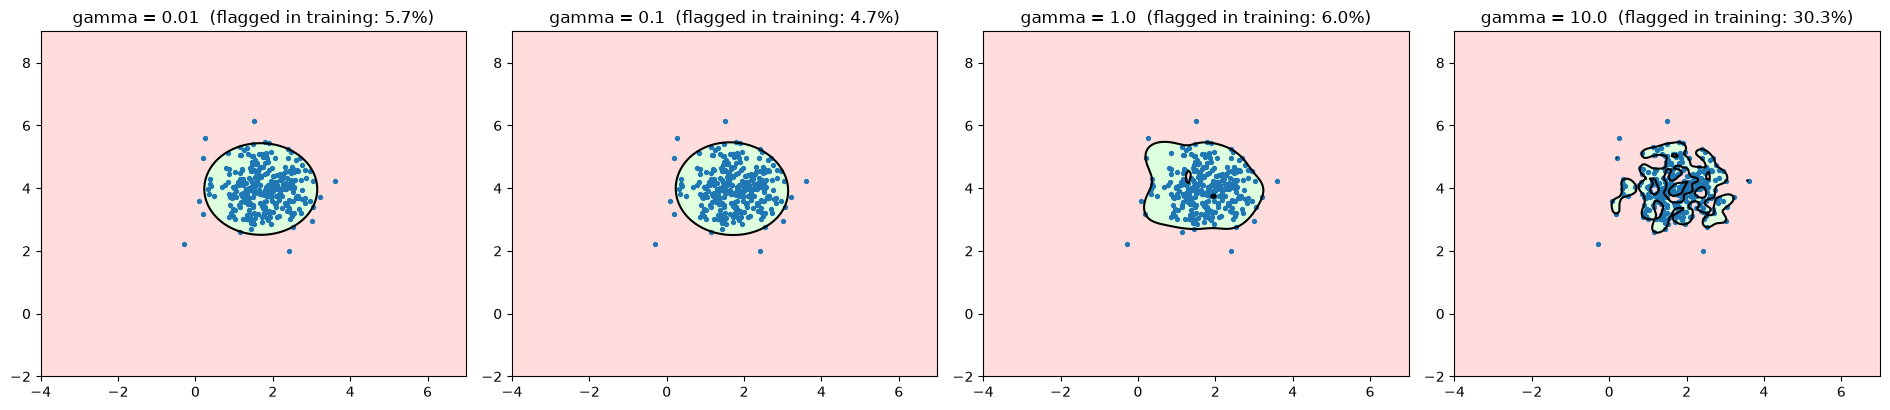

In [27]:
rows = []
for nu in [0.01, 0.05, 0.1, 0.2, 0.5]:
    m = OneClassSVM(kernel="rbf", gamma="scale", nu=nu).fit(X_train)
    rows.append({"nu": nu, "training points flagged": (m.predict(X_train) == -1).mean(), "support vectors": len(m.support_) / len(X_train),
                 "normal test pts accepted": (m.predict(X_test_normal_fixed) == 1).mean(), "novelties flagged": (m.predict(X_test_novelty) == -1).mean()})
display(pd.DataFrame(rows).set_index("nu").round(3).rename_axis(index="nu (upper bound on flagged / lower bound on SVs)"))

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
gx, gy = np.meshgrid(np.linspace(-4, 7, 200), np.linspace(-2, 9, 200))
for a, g in zip(ax, [0.01, 0.1, 1.0, 10.0]):
    m = OneClassSVM(kernel="rbf", gamma=g, nu=0.05).fit(X_train)
    a.contourf(gx, gy, m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[-100, 0, 100], colors=["#fdd", "#dfd"])
    a.contour(gx, gy, m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[0], colors="k")
    a.scatter(X_train[:, 0], X_train[:, 1], s=8); a.set_title(f"gamma = {g}  (flagged in training: {(m.predict(X_train) == -1).mean():.1%})")
plt.tight_layout(); plt.show()

`nu` is, to a good approximation, the share of training points treated as outliers (1.7%, 4.7%, 10.7%, 20.0%, 50.0% for ν = 0.01 … 0.5) and a lower bound on the share of support vectors (2.7% … 50.3%; the flagged share can exceed `nu` slightly because libsvm stops at a finite tolerance).
**Raising `nu` makes the boundary tighter:** at ν = 0.5 only 56% of fresh normal points are accepted (99% at ν = 0.01), while the share of novelties caught rises from 85% to 95%. The book states the opposite ("lower values tend to create tighter margins", a higher value makes "more data points … considered normal") — it is the other way round: a higher `nu` flags *more* normal data as novel.
`gamma` controls smoothness: 0.01 and 0.1 give a smooth ellipse around the blob (5.7% and 4.7% of the training points flagged), 1.0 a bumpy outline, and 10 a fragmented boundary that memorises individual points (30% of the *training* data fall outside it) — over-fitting.

### There's more…
* **Scaling features** — "One-Class SVMs are sensitive to feature scaling". Demonstrated below.
* **`decision_function`** — signed distance to the boundary (positive = inside).
* **High-dimensional data / cost** — training is $O(n^2)$ to $O(n^3)$; consider dimensionality reduction or a sub-sample for large *n*.

Scale sensitivity: stretch the second feature 20× (a change of units) and train the same model; the previously compact blob becomes an elongated ellipse for the RBF kernel (which uses the plain Euclidean distance):

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

stretch = np.array([1.0, 20.0])
Xtr_s, Xte_n_s, Xnov_s = X_train * stretch, X_test_normal_fixed * stretch, X_test_novelty * stretch
rows = {}
for name, est in [("unscaled (feature 2 x 20)", OneClassSVM(gamma="scale", nu=0.05)),
                  ("StandardScaler + OneClassSVM", make_pipeline(StandardScaler(), OneClassSVM(gamma="scale", nu=0.05)))]:
    est.fit(Xtr_s)
    rows[name] = {"normal test pts accepted": (est.predict(Xte_n_s) == 1).mean(), "novelties flagged": (est.predict(Xnov_s) == -1).mean()}
display(pd.DataFrame(rows).T.round(3))

,normal test pts accepted,novelties flagged
unscaled (feature 2 x 20),0.94,0.65
StandardScaler + OneClassSVM,0.95,0.90


Stretching one feature by a factor of 20 (a unit change) lowers the share of novelties caught from 90% to 65%, while the normal-acceptance rate stays at ≈ 95%: the RBF kernel's Euclidean distance is dominated by the stretched feature. Always standardise first — e.g. `make_pipeline(StandardScaler(), OneClassSVM(...))`.

### Theory — One-Class SVM
* **Formulation** (Schölkopf): find the hyperplane separating the mapped data from the origin with maximum margin, allowing a fraction $\nu$ of points on the wrong side. Equivalent (RBF kernel) to Support Vector Data Description: the smallest enclosing sphere in feature space.
* **`nu` ∈ (0, 1]:** upper bound on the fraction of training outliers, lower bound on the fraction of support vectors (verified above). **`gamma`:** kernel width — small → smooth, nearly elliptical boundary; large → follows individual points (overfits, flags more normal data).
* **Novelty (not outlier) detector:** it is meant to be fitted on (mostly) clean data and applied to new data via `predict`/`decision_function`; it does expose `predict`, unlike default LOF.
* **Requires scaling;** cost grows quickly with the number of samples.

### Hands-on workflow (book)
Generate normal-only training data, create test data with normal and anomalous points, fit `OneClassSVM` with an RBF kernel on the training data only, predict the test points, plot, and adjust `nu` and `gamma`; use `decision_function` for confidence scores.

## 4. Detecting outliers with LOF

**Summary.** LOF compares the local density of each point with that of its neighbours: a point in a region much sparser than its surroundings is an outlier. It is especially useful when the density varies across the space, where it can find *local* anomalies that global methods overlook.

### Getting ready — clusters of different densities

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

In [30]:
X, _ = make_blobs(
    n_samples=400, centers=[[0, 0], [5, 5]],
    cluster_std=[0.5, 1.5], random_state=2024
)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

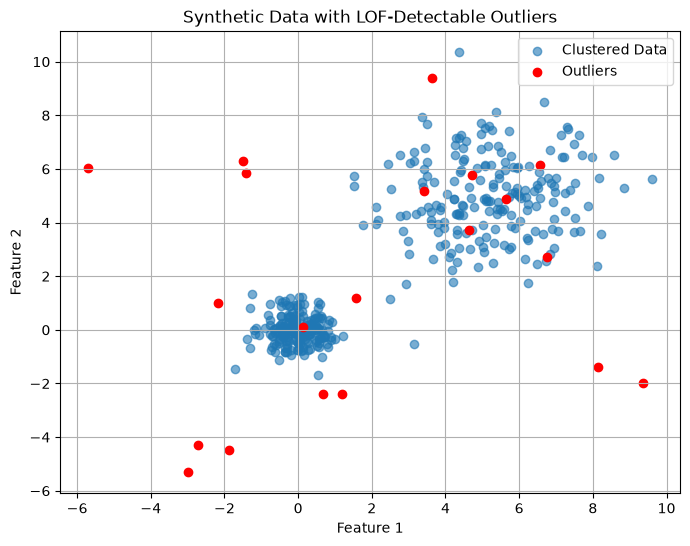

In [31]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1],
            label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1],
            color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Verification against the book:** Figure 11.7 — a tight cluster at (0, 0) (σ = 0.5), a wide one at (5, 5) (σ = 1.5) and 20 uniform outliers ✔.

### How to do it…

In [32]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

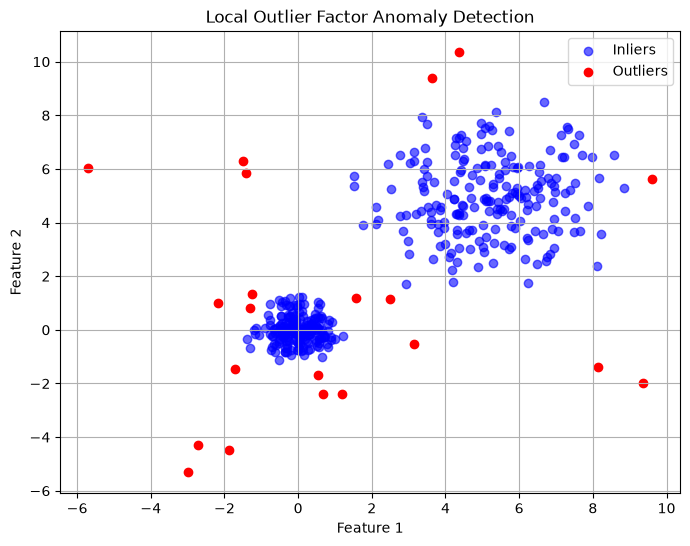

flagged: 21 | true outliers caught: 13 of 20 | normal points flagged: tight cluster 5, wide cluster 3


In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0],
            X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0],
            X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

flagged = y_pred == -1
print(f"flagged: {flagged.sum()} | true outliers caught: {flagged[400:].sum()} of 20 | normal points flagged: tight cluster {flagged[:200].sum()}, wide cluster {flagged[200:400].sum()}")

**Verification against the book:** Figure 11.8 — outliers (red) around both clusters ✔ (21 flagged: 13 of the 20 uniform points plus 8 normal points, 5 from the tight and 3 from the wide cluster).

### How it works…
The book's three steps, each computed below:
* **Local density estimation** from the distance to the *k* nearest neighbours; $k\text{-dist}(p)$ = distance to the $k$-th neighbour.
* **Reachability distance:** $\text{reach-dist}_k(p,o)=\max\{k\text{-dist}(o),\,d(p,o)\}$ smooths distances by using the neighbour's *k*-distance as a floor; $\text{lrd}_k(p)=1/\text{mean}_{o\in N_k(p)}\,\text{reach-dist}_k(p,o)$.
* **LOF score:** $\text{LOF}_k(p)=\dfrac{\text{mean}_{o\in N_k(p)}\,\text{lrd}_k(o)}{\text{lrd}_k(p)}$ — values ≫ 1 are outliers, ≈ 1 means "as dense as my neighbours".

**Extension — LOF by hand:**

In [34]:
from sklearn.neighbors import NearestNeighbors

def lof_by_hand(X, k):
    d, idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    d, idx = d[:, 1:], idx[:, 1:]                      # drop the point itself
    kdist = d[:, -1]                                   # distance to the k-th neighbour
    reach = np.maximum(d, kdist[idx])                  # reach-dist(p, o) = max(k-dist(o), d(p, o))
    lrd = 1.0 / reach.mean(axis=1)                     # local reachability density
    return lrd[idx].mean(axis=1) / lrd                 # mean neighbour density / own density

scores = lof_by_hand(X_with_outliers, 20)
print("LOF by hand == -negative_outlier_factor_ :", np.allclose(scores, -lof.negative_outlier_factor_))
print("typical normal points: median LOF =", np.median(scores[:400]).round(3), "| uniform outliers: median LOF =", np.median(scores[400:]).round(2), "| max =", scores.max().round(2))
print("flagging rule: -negative_outlier_factor_ > threshold:", np.array_equal(np.where(scores > -lof.offset_, -1, 1), y_pred), "| offset_ =", round(lof.offset_, 3))

LOF by hand == -negative_outlier_factor_ : True
typical normal points: median LOF = 1.044 | uniform outliers: median LOF = 3.03 | max = 10.04
flagging rule: -negative_outlier_factor_ > threshold: True | offset_ = -1.851


**Extension — local vs global.** LOF's selling point (and the book's recommendation) is *varying density*. Here a **local outlier** is added: a point 2.2 units from the tight cluster — about 4σ for that cluster, but a distance that is perfectly ordinary inside the wide cluster. Where does each detector rank it among the 421 points (1 = most anomalous)?

In [35]:
local_pt = np.array([[0.0, 2.2]])
Xl = np.vstack([X_with_outliers, local_pt])

lof_l = LocalOutlierFactor(n_neighbors=20).fit(Xl)
if_l = IsolationForest(random_state=0).fit(Xl)
with preserve_global_rng():
    oc_l = OneClassSVM(gamma="scale", nu=0.05).fit(Xl)
scores_local = {"LOF": -lof_l.negative_outlier_factor_, "Isolation Forest": -if_l.score_samples(Xl), "One-Class SVM": -oc_l.decision_function(Xl)}
rank = {name: int((s > s[-1]).sum()) + 1 for name, s in scores_local.items()}
display(pd.Series(rank, name="rank of the local outlier (of 421; 1 = most anomalous)").to_frame())

,rank of the local outlier (of 421; 1 = most anomalous)
LOF,16
Isolation Forest,39
One-Class SVM,133


LOF ranks the local outlier **16th** of 421, Isolation Forest **39th**, the One-Class SVM **133rd**. The point is 4σ from the tight cluster but well inside the overall spread of the data: LOF compares it with its neighbours' very high density and flags it, while global detectors judge it against the overall spread and consider it much less unusual. (The ranks above it are mostly the genuinely distant uniform outliers.)

### There's more…
* **Choosing `n_neighbors`:** small values are sensitive to local noise, large values smooth it away and approach a global method (table below).
* **Varying density:** LOF is more robust than global techniques when density differs between regions (above).
* **No `predict` on new data — by default.** The book states that LOF "is strictly an unsupervised anomaly detector used at training time … not suitable for novelty detection".

> **Book correction.** That is only true for the default `novelty=False`. With `novelty=True`, LOF fitted on clean data exposes `predict`, `decision_function` and `score_samples` for *new* points (shown in Section 1: the blob centre was accepted, (−5, −5) and (6, 6) flagged), making it a legitimate novelty detector.

In [36]:
rows = []
for k in [5, 20, 50, 100]:
    f = LocalOutlierFactor(n_neighbors=k, contamination=0.05).fit_predict(X_with_outliers) == -1
    rows.append({"n_neighbors": k, "true outliers caught (of 20)": int(f[400:].sum()), "tight-cluster pts flagged (of 200)": int(f[:200].sum()), "wide-cluster pts flagged (of 200)": int(f[200:400].sum())})
display(pd.DataFrame(rows).set_index("n_neighbors"))

,true outliers caught (of 20),tight-cluster pts flagged (of 200),wide-cluster pts flagged (of 200)
n_neighbors,,,
5,13,6,2
20,13,5,3
50,13,5,3
100,13,5,3


On this data the result barely depends on `n_neighbors` (13 of the 20 uniform points caught for every *k* from 5 to 100; 5–6 tight-cluster and 2–3 wide-cluster points flagged), because every *k* tried is smaller than the cluster sizes (200 points). The sensitivity appears when *k* is **smaller than a group of outliers**: Section 7 shows a group of 25 outliers that is invisible to LOF with *k* = 20 and found with *k* = 50.

### Theory — Local Outlier Factor
* **Idea:** an outlier is relative — a point is anomalous if its density is low *compared with its neighbours'*, so the same distance can be normal in a sparse region and anomalous next to a dense cluster.
* **Cost:** needs the *k*-nearest-neighbour graph, ≈ $O(n\log n)$ with a spatial index in low dimensions, close to $O(n^2)$ in high dimensions; memory for the neighbour lists. Distances lose meaning in high dimensions (Chapter 10).
* **Parameters:** `n_neighbors` (should exceed the size of the smallest cluster you consider normal but be smaller than the size of the smallest cluster of true anomalies), `contamination`, and the metric.
* **API:** `novelty=False` (default) → `fit_predict` / `negative_outlier_factor_` on the training set; `novelty=True` → `predict` on new data.

### Hands-on workflow (book)
Generate data with clusters of different densities plus noise, plot it, configure `LocalOutlierFactor` with `n_neighbors`, `fit_predict`, plot inliers vs outliers, vary `contamination` and `n_neighbors` and inspect the LOF score.

## 5. Evaluating outlier detection models

**Summary.** Evaluating anomaly detectors is more subtle than evaluating supervised models: outliers are rare and labels are often unavailable, so plain accuracy is useless. With labels (as in synthetic data) we use the metrics for imbalanced binary problems — precision, recall, F1, the confusion matrix, ROC-AUC.

### Getting ready — a labelled dataset
(The book draws the outliers without a seed — the numbers below match the book's because the global random stream is in the same state.)

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score
)
import seaborn as sns
import pandas as pd             # missing from the book's imports (used by the styled report below)

In [38]:
X_inliers, _ = make_blobs(
    n_samples=300, centers=[[0, 0]],
    cluster_std=0.6, random_state=2024
)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array(
    [0] * len(X_inliers) + [1] * len(X_outliers)
)  # 0 = inlier, 1 = outlier

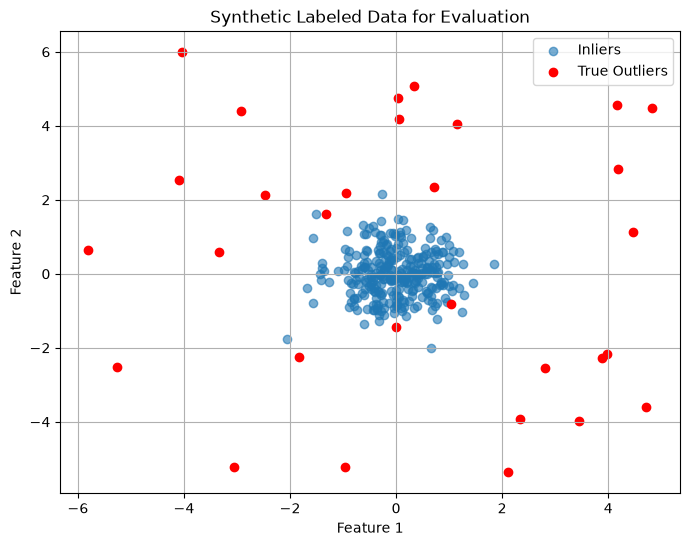

outlier share: 0.09090909090909091 | uniform points that fell within 2 units of the blob centre: 2


In [39]:
plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0],
            X[y_true == 0][:, 1],
            label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0],
            X[y_true == 1][:, 1],
            color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print("outlier share:", len(X_outliers) / len(X), "| uniform points that fell within 2 units of the blob centre:", (np.linalg.norm(X_outliers, axis=1) < 2).sum())

**Verification against the book:** Figure 11.9 — blob plus 30 uniform outliers ✔ (9.1% outliers; `contamination=0.09` in the next step matches this share, which is not available in real projects).

### How to do it…

In [40]:
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(
    y_pred == 1, 0, 1
)  # convert to 0 = inlier, 1 = outlier

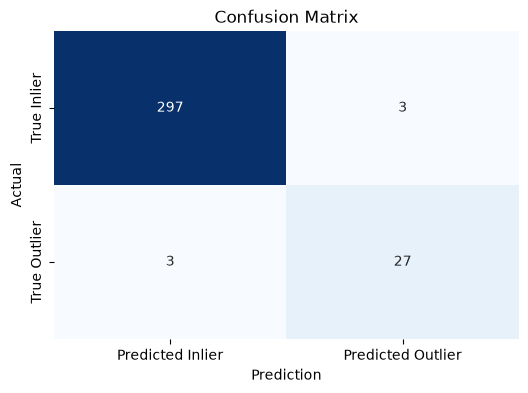

[[297   3]
 [  3  27]]


In [41]:
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Predicted Inlier', 'Predicted Outlier'],
    yticklabels=['True Inlier', 'True Outlier']
)
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
print(cm)

In [42]:
report = classification_report(
    y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("ROC-AUC Score:",
      roc_auc_score(y_true, model.decision_function(X)))

,precision,recall,f1-score,support
0,0.990,0.990,0.990,300
1,0.900,0.900,0.900,30
accuracy,0.982,0.982,0.982,1
macro avg,0.945,0.945,0.945,330
weighted avg,0.982,0.982,0.982,330


ROC-AUC Score: 0.005111111111111106


**Verification against the book:** Figure 11.10 — confusion matrix `[[297, 3], [3, 27]]` ✔; Figure 11.11 — precision/recall/F1 0.990 (class 0) and 0.900 (class 1), accuracy 0.982, macro 0.945 ✔; and the printed **ROC-AUC Score: 0.00511111…** ✔ reproduced to every digit. (The `support` shown for the *accuracy* row is the accuracy rounded to 0 decimals by `'{:.0f}'`.)

> **Book correction (the AUC is inverted).** An AUC of **0.005** is not "poor": it is almost perfectly *wrong-way-round* (1 − 0.005 = 0.995). `roc_auc_score(y_true, scores)` expects **higher score = more likely to be class 1** (outlier). But for scikit-learn's detectors `decision_function` is **higher = more normal** (negative = outlier). The book passes it unchanged, then describes the number as "the model's ability to distinguish classes". The score must be negated:

In [43]:
auc_book = roc_auc_score(y_true, model.decision_function(X))
auc_fixed = roc_auc_score(y_true, -model.decision_function(X))
print(f"as printed in the book (higher = more normal): {auc_book:.4f}")
print(f"negated (higher = more anomalous)            : {auc_fixed:.4f}   = 1 - {auc_book:.4f}")
print("same thing with score_samples (also higher = more normal):", round(roc_auc_score(y_true, -model.score_samples(X)), 4))

as printed in the book (higher = more normal): 0.0051
negated (higher = more anomalous)            : 0.9949   = 1 - 0.0051


same thing with score_samples (also higher = more normal): 0.9949


### How it works…
* **Precision** — of the points predicted as outliers, the share that really are; **Recall** — of the real outliers, the share found; **F1** — their harmonic mean (useful under class imbalance); **Confusion matrix** — the full table; **ROC-AUC** — the probability that a random outlier is ranked above a random inlier.
* Without labels (the usual case) the book mentions expert validation, reconstruction error (autoencoders) or proxy metrics such as prediction stability.

**Extension — why accuracy is a poor metric here, and what the other numbers mean.** Predicting "inlier" for everything gets 90.9% accuracy with zero recall; the detector's 98.2% is only 7 points better but finds 90% of the outliers. And the metrics can be recomputed from the matrix:

In [44]:
tn, fp, fn, tp = cm.ravel()
print(f"accuracy of 'everything is an inlier': {300 / 330:.3f}   (the detector: {(tn + tp) / 330:.3f})")
print(f"outlier class: precision = {tp}/{tp + fp} = {tp / (tp + fp):.3f} | recall = {tp}/{tp + fn} = {tp / (tp + fn):.3f} | F1 = {2 * tp / (2 * tp + fp + fn):.3f}")
print("with contamination = 0.09 the detector flags exactly", int((y_pred == -1).sum()), "points (0.09 x 330 = 29.7), so FP = FN =", fp, ": precision equals recall by construction")

accuracy of 'everything is an inlier': 0.909   (the detector: 0.982)
outlier class: precision = 27/30 = 0.900 | recall = 27/30 = 0.900 | F1 = 0.900
with contamination = 0.09 the detector flags exactly 30 points (0.09 x 330 = 29.7), so FP = FN = 3 : precision equals recall by construction


**Extension — threshold tuning and the contamination trap.** The model ranks points; `contamination` only picks the cut-off. Precision/recall as the cut-off moves (the true share is 9.1%), and the precision-recall curve of the continuous score:

,flagged,precision,recall,F1
contamination,,,,
0.02,7,1.000,0.233,0.378
0.05,17,1.000,0.567,0.723
0.09,30,0.900,0.900,0.900
0.15,50,0.580,0.967,0.725
0.25,83,0.361,1.000,0.531


average precision (area under the PR curve): 0.966 | ROC-AUC: 0.995


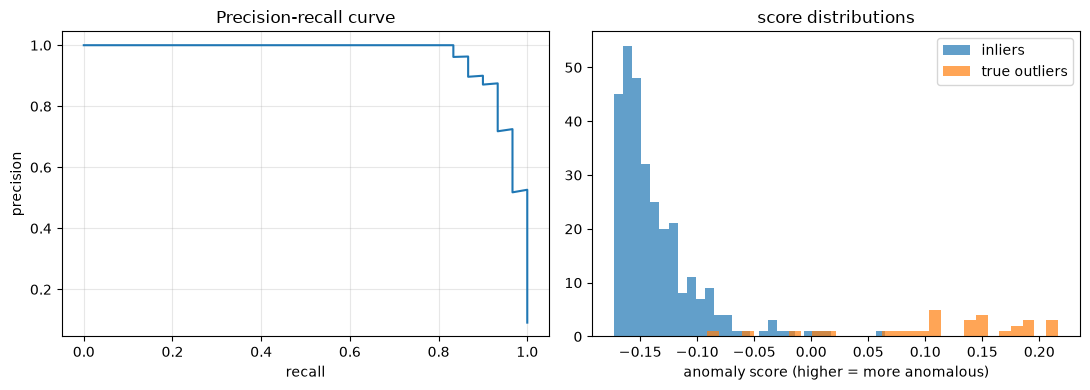

In [45]:
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score, f1_score

rows = []
for cont in [0.02, 0.05, 0.09, 0.15, 0.25]:
    m = IsolationForest(contamination=cont, random_state=2024).fit(X)
    yb = (m.predict(X) == -1).astype(int)
    rows.append({"contamination": cont, "flagged": int(yb.sum()), "precision": precision_score(y_true, yb), "recall": recall_score(y_true, yb), "F1": f1_score(y_true, yb)})
display(pd.DataFrame(rows).set_index("contamination").round(3))

scores_out = -model.decision_function(X)
prec, rec, _ = precision_recall_curve(y_true, scores_out)
print("average precision (area under the PR curve):", round(average_precision_score(y_true, scores_out), 3), "| ROC-AUC:", round(auc_fixed, 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rec, prec); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall curve"); ax[0].grid(alpha=0.3)
ax[1].hist(scores_out[y_true == 0], bins=30, alpha=0.7, label="inliers"); ax[1].hist(scores_out[y_true == 1], bins=30, alpha=0.7, label="true outliers")
ax[1].set_xlabel("anomaly score (higher = more anomalous)"); ax[1].legend(); ax[1].set_title("score distributions")
plt.tight_layout(); plt.show()

`contamination` is only a threshold, and the table shows the trade-off: at 2% only 7 points are flagged (precision 1.0, recall 0.23); at 25% 83 points (recall 1.0, precision 0.36); the best F1 (0.90) is at the true share of 9% — which a real project does not know. The ranking itself is excellent (ROC-AUC 0.995, average precision 0.966), so the sensible workflow is to **rank by score and set the cut-off by cost** (right panel: the two score distributions overlap only slightly).

**Extension — the three detectors on the same labelled data**, each scored with the *correct* sign (anomaly score = higher means more anomalous):

In [46]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

with preserve_global_rng():
    oc_scores = -OneClassSVM(gamma="scale", nu=0.09).fit(X).decision_function(X)
det = {"Isolation Forest": -IsolationForest(random_state=2024).fit(X).score_samples(X),
       "LOF (k=20)": -LocalOutlierFactor(n_neighbors=20).fit(X).negative_outlier_factor_,
       "One-Class SVM": oc_scores}
display(pd.DataFrame({k: {"ROC-AUC": roc_auc_score(y_true, v), "average precision": average_precision_score(y_true, v)} for k, v in det.items()}).T.round(3))

,ROC-AUC,average precision
Isolation Forest,0.995,0.966
LOF (k=20),0.993,0.959
One-Class SVM,0.910,0.844


Isolation Forest (AUC 0.995) and LOF (0.993) are practically equal on this easy single-blob problem; the One-Class SVM is clearly behind (AUC 0.910, average precision 0.844) with default settings and no tuning — it is the detector that most needs `gamma`/`nu` and scaling care (Section 3).

### There's more…
* **Use-case costs:** in fraud detection a missed fraud (false negative) may cost far more than a false alarm — choose the threshold accordingly.
* **Threshold tuning:** use `decision_function` / scores to trade precision against recall (above).
* **Cross-validation:** stratified *k*-fold on labelled anomaly data gives more robust comparisons.

### Theory — evaluating anomaly detection
* **Imbalance:** outliers are rare, so use precision/recall/F1 or average precision, not accuracy; ROC-AUC is insensitive to the base rate, average precision is not (it reflects what an analyst would see).
* **Sign conventions:** scikit-learn's detectors return *higher = more normal* (`decision_function`, `score_samples`) and `-1` for outliers; metrics for the "positive = anomaly" class need the negated score.
* **Transductive vs inductive:** outlier detection is evaluated on the data it was fitted on; novelty detection must be evaluated on *held-out* data.
* **Unlabelled reality:** rely on domain experts, stability across seeds/samples, and downstream-task performance.

### Hands-on workflow (book)
Generate or load labelled inliers and outliers, fit `IsolationForest()`, convert predictions to 0/1, evaluate with `confusion_matrix`, `classification_report` and ROC-AUC from `decision_function` (negated!), and explore contamination levels and threshold tuning.

## 6. Handling detected outliers

**Summary.** Once outliers are found, what to do depends on context: they can be **informative** (fraud cases) or **disruptive** (sensor glitches). The book shows common strategies — removal, replacement, capping (winsorisation) and flagging.

### Getting ready
The same blob-plus-30-outliers construction (a fresh unseeded draw, continuing the random stream), with outliers detected by Isolation Forest.

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

In [48]:
X_inliers, _ = make_blobs(
    n_samples=300, centers=[[0, 0]],
    cluster_std=0.6, random_state=2024
)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

In [49]:
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1
print("detected outliers:", outlier_mask.sum(), "| true outliers among them:", outlier_mask[300:].sum(), "| inliers wrongly flagged:", outlier_mask[:300].sum())

detected outliers: 30 | true outliers among them: 27 | inliers wrongly flagged: 3


### How to do it…
**1. Remove** the flagged rows, **2. replace** them by the feature-wise median of the non-outliers, **3. cap** every feature at its 5th and 95th percentile:

In [50]:
X_cleaned = X[~outlier_mask]

In [51]:
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

In [52]:
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

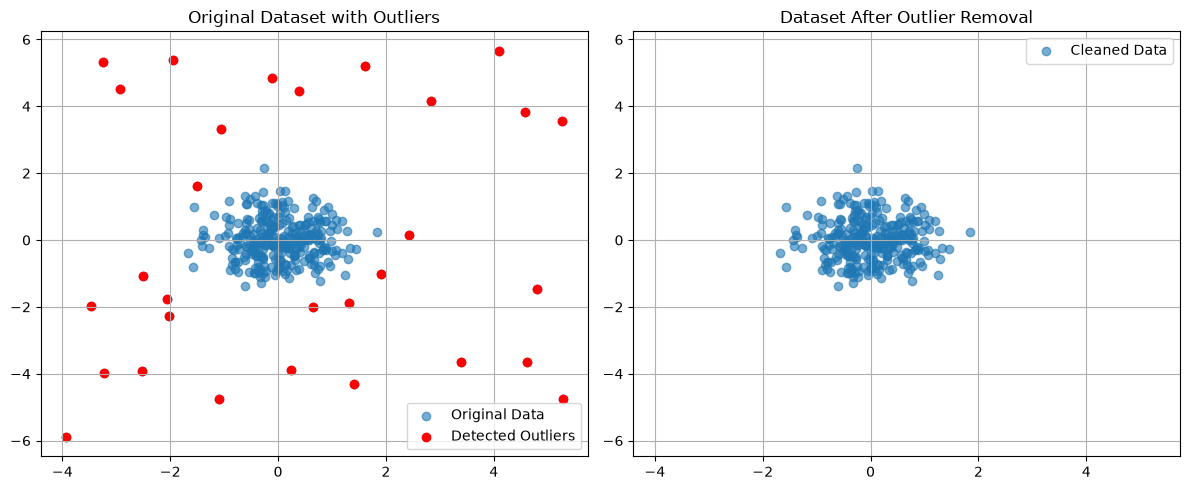

shapes -> original (330, 2) | removed (300, 2) | replaced (330, 2) | capped (330, 2)


In [53]:
plt.figure(figsize=(12, 5))
ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1],
            label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0],
            X[outlier_mask][:, 1],
            color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)
ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1],
            label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)
ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())
plt.tight_layout()
plt.show()
print("shapes -> original", X.shape, "| removed", X_cleaned.shape, "| replaced", X_replaced.shape, "| capped", X_capped.shape)

**Verification against the book:** Figure 11.12 — the left panel shows the data with red detected outliers, the right panel the "much denser" cleaned data on the same axes ✔ (330 → 300 rows).

**Check the other two strategies** — the book computes `X_replaced` and `X_capped` but never shows or discusses them. How many values did each change, and what happened to the *normal* points?

In [54]:
changed_replace = (X_replaced != X).any(axis=1)
changed_cap = (X_capped.values != X).any(axis=1)
print(f"median replacement : changed rows {changed_replace.sum()} (all flagged); the 'replaced' outliers now sit on ONE point {median_vals.round(3)} (duplicates)")
print(f"capping 5%-95%     : changed rows {changed_cap.sum()} of {len(X)} | among the 300 normal rows: {changed_cap[:300].sum()} | among the 30 true outliers: {changed_cap[300:].sum()}")
print("range of the outliers after capping:", X_capped.min().round(2).tolist(), "to", X_capped.max().round(2).tolist(), "(original", X.min(axis=0).round(2).tolist(), "to", X.max(axis=0).round(2).tolist(), ")")

median replacement : changed rows 30 (all flagged); the 'replaced' outliers now sit on ONE point [-0.007 -0.012] (duplicates)
capping 5%-95%     : changed rows 47 of 330 | among the 300 normal rows: 19 | among the 30 true outliers: 28
range of the outliers after capping: [-1.39, -1.26] to [1.28, 1.31] (original [-3.94, -5.89] to [5.28, 5.66] )


The detector flagged 30 points: 27 true outliers and 3 normal ones. **Median replacement** changes only the 30 flagged rows — and puts all of them on one point (−0.007, −0.012): 30 duplicates at the centre of the blob. **Capping** at the 5th/95th percentiles changes 47 rows: 28 of the 30 true outliers (pulled in from about ±6 to ±1.3) but also **19 of the 300 normal points** — it trims the tails of the normal data whether or not they were flagged, which the book does not mention.

### How it works…
The book's guidance:
* **Removal** — appropriate when outliers are noise or corrupted records; but excessive removal discards signal.
* **Replacement** — replaces outliers by the mean, median or another statistic: preserves the dataset size but may introduce bias.
* **Capping (winsorisation)** — restricts values to a range; retains the ordering.
* **Flagging** — keep the outliers, add a new feature marking them so the model can learn their behaviour.

**Extension — does it matter downstream?** The book lists "compare model performance before and after" as an exercise without showing it. A regression with 30 contaminating points (high-leverage, wrong-way) in 300: the true relationship is $y = 1 + 2x$. Each strategy is fitted on the contaminated training data (outliers detected on $[x, y]$ with Isolation Forest) and judged on a *clean* test set:

In [55]:
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(0)
n = 300
x_in = rng.normal(size=n); y_in = 1 + 2 * x_in + rng.normal(scale=0.5, size=n)
x_out = rng.normal(loc=3.0, scale=0.5, size=30); y_out = rng.normal(loc=-8.0, scale=1.0, size=30)          # high-leverage, wrong-way outliers
x_tr = np.r_[x_in, x_out]; y_tr = np.r_[y_in, y_out]
x_te = rng.normal(size=1000); y_te = 1 + 2 * x_te + rng.normal(scale=0.5, size=1000)                     # clean test set

D = np.c_[x_tr, y_tr]
mask = IsolationForest(contamination=0.09, random_state=0).fit(D).predict(D) == -1
print("detector: flagged", mask.sum(), "| true outliers among them:", mask[n:].sum(), "| inliers wrongly flagged:", mask[:n].sum())

def evaluate(name, Xf, yf, model=None):
    model = model or LinearRegression()
    model.fit(Xf.reshape(-1, 1), yf)
    coef = model.coef_[0]; icpt = model.intercept_
    return {"strategy": name, "slope (true 2)": coef, "intercept (true 1)": icpt, "clean-test MSE": mean_squared_error(y_te, model.predict(x_te.reshape(-1, 1)))}

rows = [evaluate("keep everything (no handling)", x_tr, y_tr),
        evaluate("remove flagged rows", x_tr[~mask], y_tr[~mask])]
med = np.median(D[~mask], axis=0); Dr = D.copy(); Dr[mask] = med
rows.append(evaluate("replace flagged rows by the median", Dr[:, 0], Dr[:, 1]))
lo, hi = np.quantile(D, 0.05, axis=0), np.quantile(D, 0.95, axis=0); Dc = np.clip(D, lo, hi)
rows.append(evaluate("cap at 5th/95th percentile", Dc[:, 0], Dc[:, 1]))
rows.append(evaluate("keep everything + HuberRegressor (robust model)", x_tr, y_tr, HuberRegressor()))
rows.append(evaluate("oracle: remove the true 30 outliers", x_in, y_in))
display(pd.DataFrame(rows).set_index("strategy").round(3))

detector: flagged

 30 | true outliers among them: 15 | inliers wrongly flagged: 15


,slope (true 2),intercept (true 1),clean-test MSE
strategy,,,
keep everything (no handling),-0.153,0.154,5.540
remove flagged rows,0.198,0.471,3.749
replace flagged rows by the median,0.194,0.502,3.731
cap at 5th/95th percentile,-0.169,0.144,5.624
keep everything + HuberRegressor (robust model),1.791,0.916,0.304
oracle: remove the true 30 outliers,2.020,0.996,0.252


The detector (Isolation Forest on [x, y]) found only 15 of the 30 contaminating points and wrongly flagged 15 normal ones: the 30 outliers form a tight *group*, which hides them from each other (**masking**). Consequences:
* keeping everything gives slope −0.15 (true 2.0) and a clean-test MSE of 5.54;
* **removing** or **replacing** the flagged rows improves the MSE to ≈ 3.7, but the slope is still 0.2 — the half that were missed still dominate;
* **capping** at 5/95% is no better than doing nothing (MSE 5.62);
* the **robust model** — `HuberRegressor` on the *unhandled* data — reaches slope 1.79 and MSE 0.30, almost the oracle (the true outliers removed: slope 2.02, MSE 0.25).

Handling is only as good as the detector, and when anomalies come in groups a robust estimator can beat "detect and remove". Judge each strategy on clean validation data whenever possible.

**Flagging** keeps all rows and adds the detector's verdict as a feature:

In [56]:
X_flagged = np.c_[X, outlier_mask.astype(int)]
print("flagged design matrix:", X_flagged.shape, "| last column = is_outlier, sum =", int(X_flagged[:, -1].sum()))

flagged design matrix: (330, 3) | last column = is_outlier, sum = 30


### There's more…
The book recommends consulting domain experts, wrapping the handling in scikit-learn's `FunctionTransformer()` or a `Pipeline`, and considering imputation vs deletion.

> **Book correction (pipeline integration has a catch).** Strategies that *keep the number of rows* (replacement, capping, flagging) fit naturally into a `Pipeline`. **Removal does not:** a transformer cannot drop rows from `X` without also dropping them from `y`, and scikit-learn transformers do not touch `y`:

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

def drop_outlier_rows(A):
    keep = IsolationForest(contamination=0.09, random_state=0).fit(A).predict(A) == 1
    return A[keep]

pipe = Pipeline([("drop", FunctionTransformer(drop_outlier_rows)), ("reg", LinearRegression())])
try:
    pipe.fit(x_tr.reshape(-1, 1), y_tr)
except ValueError as e:
    print("ValueError:", str(e)[:120])

ValueError: Found input variables with inconsistent numbers of samples: [300, 330]


Removal inside a cross-validated workflow needs a *sampler* that can resample `X` and `y` together (the `imbalanced-learn` package provides this pattern) or an explicit outlier-removal step outside the pipeline applied **only to the training folds**.

### Theory — handling outliers
* **First ask why:** error (fix or remove), rare-but-real event (keep, maybe model separately, e.g. fraud), or a different population (segment).
* **Removal** loses rows and can bias the sample; **replacement by a central value** creates artificial duplicates at the centre; **winsorisation** touches every point beyond the percentile — *including normal ones* (10% of each column here) — regardless of whether the detector called them outliers; **flagging** keeps information but needs a model that can use it; a **robust model** (Huber, quantile regression, tree ensembles) can make hard decisions unnecessary.
* **Do it inside cross-validation** so test folds are never used to decide what counts as an outlier.

### Hands-on workflow (book)
Inject outliers with `make_blobs` + uniform noise, fit `IsolationForest()` and keep a mask, remove / replace / cap, plot before and after, compare downstream model results and wrap the chosen strategy in a pipeline — done above (with the pipeline caveat).

## 7. Choosing the right detection technique

**Summary.** The best method depends on the data, the availability of labels and the use case. The book compares the three detectors by assumption, scalability, dimensionality, interpretability and whether they can predict for new data.

### Getting ready
The book's comparison table of methods:

In [58]:
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

In [59]:
data = {
    "Algorithm": ["Isolation Forest",
                  "Local Outlier Factor",
                  "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes",
                                   "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}
summary_df = pd.DataFrame(data)
summary_df.set_index("Algorithm", inplace=True)
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


**Verification against the book:** Figure 11.13 — the same table ✔. It is a set of claims, not results, so each can be tested. Four of the cells are questionable and are checked below:
* *"Supports New Predictions: LOF — No"* → false with `novelty=True` (Section 4).
* *"Learns From Unlabeled Data: One-Class SVM — No (novelty only)"* → the One-Class SVM needs **no labels at all** (it is unsupervised); it should be fitted on *clean* data, but the labels are never used.
* *"Handles High Dimensions"*, *"Scales to Large Data"* and *"Robust to Varying Densities"* → measured below.

### How to do it…
The book's decision rules, as code:

In [60]:
# Isolation Forest is preferred
model = IsolationForest(contamination=0.1, random_state=2024)

In [61]:
# Local Outlier Factor is better suited
model = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

In [62]:
# One-Class SVM enables novelty detection
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)

### How it works…
The book: *Isolation Forest* — general purpose, large high-dimensional data, may underperform with varying densities; *LOF* — local deviations, powerful for non-uniform data, cannot predict unseen data; *One-Class SVM* — novelty detection with only normal training data, expensive on large data and sensitive to scaling; "when in doubt, start with Isolation Forest".

**Extension — testing the table.** Three labelled scenarios, each detector scored by ROC-AUC with the correct sign (outliers are known only for evaluation):
* **A — one blob, uniform outliers** (the chapter's setting);
* **B — varying density with local outliers:** a tight cluster (σ = 0.2) next to a very wide one (σ = 4), with 15 outliers placed 1.0–1.6 units from the tight cluster (5–8σ for it, but closer than the typical neighbour spacing in the wide cluster);
* **C — 50 dimensions:** standard-normal inliers, 25 outliers shifted by +4σ in 5 of the 50 dimensions (an outlier in a *subspace*).

,Isolation Forest,LOF (k=20),LOF (k=50),One-Class SVM
A: one blob + uniform outliers,0.958,0.949,0.951,0.914
B: varying density + local outliers,0.741,0.991,0.983,0.870
"C: 50-D, subspace outliers",0.950,0.271,0.998,0.888


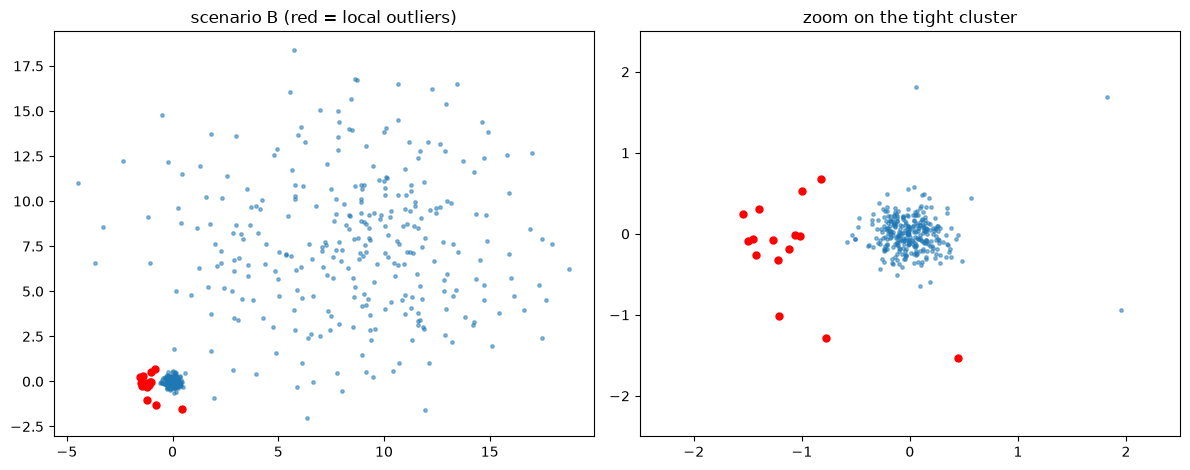

In [63]:
from sklearn.metrics import roc_auc_score

def make_scenarios(seed=0):
    rng = np.random.default_rng(seed)
    out = {}
    # A
    inl = rng.normal(0, 0.6, size=(300, 2)); o = rng.uniform(-6, 6, size=(30, 2))
    out["A: one blob + uniform outliers"] = (np.vstack([inl, o]), np.r_[np.zeros(300), np.ones(30)])
    # B
    tight = rng.normal(0, 0.2, size=(300, 2)); wide = rng.normal(0, 4, size=(300, 2)) + np.array([8, 8])
    ang = rng.uniform(np.pi * 0.75, np.pi * 1.75, 15); rad = rng.uniform(1.0, 1.6, 15)
    local = np.c_[rad * np.cos(ang), rad * np.sin(ang)]
    out["B: varying density + local outliers"] = (np.vstack([tight, wide, local]), np.r_[np.zeros(600), np.ones(15)])
    # C
    inl = rng.normal(size=(500, 50)); o = rng.normal(size=(25, 50)); o[:, :5] += 4.0
    out["C: 50-D, subspace outliers"] = (np.vstack([inl, o]), np.r_[np.zeros(500), np.ones(25)])
    return out

def score_all(Xd, seed=0):
    return {"Isolation Forest": -IsolationForest(random_state=seed).fit(Xd).score_samples(Xd),
            "LOF (k=20)": -LocalOutlierFactor(n_neighbors=20).fit(Xd).negative_outlier_factor_,
            "LOF (k=50)": -LocalOutlierFactor(n_neighbors=50).fit(Xd).negative_outlier_factor_,
            "One-Class SVM": -OneClassSVM(gamma="scale", nu=0.05).fit(Xd).decision_function(Xd)}

scen = make_scenarios()
res = {name: {d: roc_auc_score(yy, s) for d, s in score_all(Xd).items()} for name, (Xd, yy) in scen.items()}
display(pd.DataFrame(res).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
XB, yB = scen["B: varying density + local outliers"]
ax[0].scatter(XB[yB == 0, 0], XB[yB == 0, 1], s=6, alpha=0.5); ax[0].scatter(XB[yB == 1, 0], XB[yB == 1, 1], s=25, c="red"); ax[0].set_title("scenario B (red = local outliers)")
ax[1].scatter(XB[yB == 0, 0], XB[yB == 0, 1], s=6, alpha=0.5); ax[1].scatter(XB[yB == 1, 0], XB[yB == 1, 1], s=25, c="red"); ax[1].set_xlim(-2.5, 2.5); ax[1].set_ylim(-2.5, 2.5); ax[1].set_title("zoom on the tight cluster")
plt.tight_layout(); plt.show()

Reading the table (ROC-AUC; 1 = perfect, 0.5 = chance):
* **A — global outliers:** all three work (Isolation Forest 0.958, LOF 0.95, One-Class SVM 0.914).
* **B — varying density with local outliers:** **LOF 0.99 vs Isolation Forest 0.74** (One-Class SVM 0.87): the book's "Isolation Forest: not robust to varying densities, LOF: robust" is confirmed.
* **C — 50 dimensions, subspace outliers:** Isolation Forest 0.95; **LOF with the book's *k* = 20 scores 0.27 — worse than chance — but with *k* = 50 it scores 0.998.** The 25 outliers form a group larger than 20 points, so each one has 20 neighbours that are also outliers and looks like a normal member of a small dense cluster: **masking**, not dimensionality. So "LOF does not handle high dimensions" is *not* confirmed; what matters is *k* relative to the size of the anomalous group. The One-Class SVM gets 0.89.

**Scalability:** wall-clock time to fit **and score** *n* points of a 2-D blob as *n* grows (one run, orders of magnitude only; the One-Class SVM and the 20-D runs stop at 16,000 points):

In [64]:
import time

def time_fit_score(est, score, Xn):
    t0 = time.perf_counter()
    est.fit(Xn)
    if score is not None:
        score(est, Xn)
    return time.perf_counter() - t0

rows = {}
for n in [1000, 4000, 16000, 64000]:
    Xn = np.random.default_rng(1).normal(size=(n, 2))
    rows[n] = {"Isolation Forest, 2-D": time_fit_score(IsolationForest(random_state=0), lambda m, A: m.score_samples(A), Xn),
               "LOF (k=20), 2-D": time_fit_score(LocalOutlierFactor(n_neighbors=20), None, Xn),          # fit already scores the training set
               "One-Class SVM, 2-D": np.nan if n > 16000 else time_fit_score(OneClassSVM(gamma="scale", nu=0.05), lambda m, A: m.decision_function(A), Xn)}
    if n <= 16000:
        X20 = np.random.default_rng(1).normal(size=(n, 20))
        rows[n]["Isolation Forest, 20-D"] = time_fit_score(IsolationForest(random_state=0), lambda m, A: m.score_samples(A), X20)
        rows[n]["LOF (k=20), 20-D"] = time_fit_score(LocalOutlierFactor(n_neighbors=20), None, X20)
display(pd.DataFrame(rows).round(2).rename_axis(columns="n samples"))

n samples,1000,4000,16000,64000
"Isolation Forest, 2-D",0.16,0.22,0.29,0.59
"LOF (k=20), 2-D",0.00,0.02,0.08,0.36
"One-Class SVM, 2-D",0.01,0.10,1.45,NaN
"Isolation Forest, 20-D",0.16,0.19,0.28,NaN
"LOF (k=20), 20-D",0.02,0.04,0.27,NaN


Fit-and-score time: the **One-Class SVM** is clearly quadratic (0.01 s → 0.10 s → ≈ 1.5 s for 1,000 → 4,000 → 16,000 points) and impractical far beyond that. **Isolation Forest** is nearly flat then linear (0.16 s → 0.59 s from 1,000 to 64,000 points; a fixed tree-building cost dominates at small *n*). **LOF** was the *fastest* in every run — 0.36 s at 64,000 points in 2-D and 0.27 s at 16,000 points in 20-D — thanks to the spatial index. So the table's "LOF: does not scale" is not borne out up to these sizes; it concerns the memory and brute-force distance cost in very high dimensions and for very large *n*, which were not tested. The robust conclusions are: avoid the One-Class SVM for large data; Isolation Forest has the most predictable cost.

### There's more…
* **Hybrid strategies** — combine detectors (e.g. LOF and Isolation Forest) so that both global and local anomalies are caught.
* **Explainability** — the book credits Isolation Forest with `feature_importances_`; it has none (Section 2).
* **Benchmarking** — precision-recall curves, ROC-AUC or domain-specific criteria (Section 5).

### Theory — choosing a detector
1. Do you need to score **new** points? → One-Class SVM, Isolation Forest, or LOF with `novelty=True`.
2. Is the data large or high-dimensional? → Isolation Forest first.
3. Do clusters have **very different densities** and anomalies hide next to dense clusters? → LOF (or another local method).
4. Do you have only clean "normal" data? → One-Class SVM / LOF(novelty=True); scale first.
5. Always **evaluate on whatever labels or expert judgement exist**, rank by score rather than relying on `contamination`, and combine detectors when the cost of a miss is high.

### Hands-on workflow (book)
Build datasets with known anomalies, fit Isolation Forest, LOF and One-Class SVM on the same data, compare predictions with the truth (`confusion_matrix`, ROC-AUC, `classification_report`), summarise strengths and trade-offs in a DataFrame, try ensembles or voting, and weigh operational needs (speed, explainability) — as in the experiments above.

## 8. Practical exercises in novelty and outlier detection

The book describes three exercises with implementation steps only (no code). They are implemented here with seeded generators (separate from the global random state).

### Exercise 1: Applying Isolation Forest to a real-world-like dataset
Steps (book): load the libraries, generate synthetic data with inliers and outliers, scale the data, apply Isolation Forest, evaluate, print a classification report as a styled DataFrame. Three features with very different scales (as in real data, e.g. transaction amount, age, number of items):

In [65]:
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(2024)
inl = np.c_[rng.normal(120, 30, 950), rng.normal(40, 8, 950), rng.normal(3, 1, 950)]          # 950 normal records
out = np.c_[rng.uniform(300, 900, 50), rng.uniform(18, 75, 50), rng.uniform(8, 25, 50)]        # 50 anomalous records
X_ex1 = np.vstack([inl, out]); y_ex1 = np.r_[np.zeros(950), np.ones(50)]

X_ex1_s = StandardScaler().fit_transform(X_ex1)
iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=2024).fit(X_ex1_s)
pred = (iso.predict(X_ex1_s) == -1).astype(int)

rep = pd.DataFrame(classification_report(y_ex1, pred, output_dict=True, target_names=["inlier", "outlier"])).transpose()
display(rep.style.background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"]).format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))
auc_scaled = roc_auc_score(y_ex1, -iso.decision_function(X_ex1_s))
auc_raw = roc_auc_score(y_ex1, -IsolationForest(n_estimators=200, random_state=2024).fit(X_ex1).decision_function(X_ex1))
print(f"ROC-AUC (negated score) scaled: {auc_scaled:.3f} | on the unscaled features: {auc_raw:.3f}")

,precision,recall,f1-score,support
inlier,1.000,1.000,1.000,950
outlier,1.000,1.000,1.000,50
accuracy,1.000,1.000,1.000,1
macro avg,1.000,1.000,1.000,1000
weighted avg,1.000,1.000,1.000,1000


ROC-AUC (negated score) scaled: 1.000 | on the unscaled features: 1.000


Perfect result — all 50 anomalies found, no false alarm, ROC-AUC 1.000 with or without scaling — because the anomalies were generated 10σ or more away on the amount feature: easy by construction. Isolation Forest does not care about feature scale (random single-feature splits), so the book's "scale the data" step is harmless here but unnecessary for this model (it matters for LOF and the One-Class SVM).

### Exercise 2: Using LOF on a network-intrusion-like dataset
Steps (book): load the libraries, generate clustered data with synthetic noise, scale the data, apply LOF, evaluate the predictions. Three traffic profiles (imbalanced clusters of different spread) plus injected anomalies:

[[988  12]
 [ 12  28]]
              precision    recall  f1-score   support

      normal      0.988     0.988     0.988      1000
      attack      0.700     0.700     0.700        40

    accuracy                          0.977      1040
   macro avg      0.844     0.844     0.844      1040
weighted avg      0.977     0.977     0.977      1040

ROC-AUC with the negative-outlier-factor score: 0.938
injected attacks lying inside a normal cluster: 12 | missed among them: 11 | attacks outside all clusters that were missed: 1


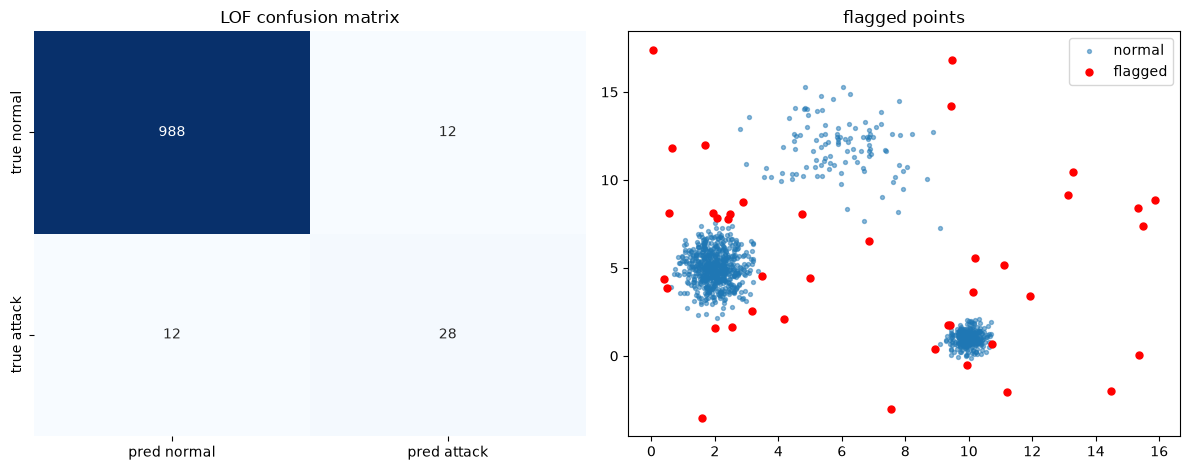

In [66]:
rng = np.random.default_rng(2024)
web = rng.normal([2, 5], [0.5, 1.0], size=(600, 2)); mail = rng.normal([10, 1], [0.3, 0.4], size=(300, 2)); ssh = rng.normal([6, 12], [1.2, 1.5], size=(100, 2))
attack = rng.uniform([-2, -4], [16, 18], size=(40, 2))
X_ex2 = np.vstack([web, mail, ssh, attack]); y_ex2 = np.r_[np.zeros(1000), np.ones(40)]
X_ex2_s = StandardScaler().fit_transform(X_ex2)

lof2 = LocalOutlierFactor(n_neighbors=20, contamination=40 / 1040)
pred2 = (lof2.fit_predict(X_ex2_s) == -1).astype(int)
cm2 = confusion_matrix(y_ex2, pred2)
print(cm2)
print(classification_report(y_ex2, pred2, target_names=["normal", "attack"], digits=3))
print("ROC-AUC with the negative-outlier-factor score:", round(roc_auc_score(y_ex2, -lof2.negative_outlier_factor_), 3))

centres = np.array([[2, 5], [10, 1], [6, 12]]); sds = np.array([[0.5, 1.0], [0.3, 0.4], [1.2, 1.5]])
inside = np.min(np.sqrt((((attack[:, None, :] - centres[None]) / sds[None]) ** 2).sum(axis=2)), axis=1) < 3         # attack points lying within 3 sigma of a cluster centre
caught = pred2[1000:] == 1
print(f"injected attacks lying inside a normal cluster: {inside.sum()} | missed among them: {(~caught & inside).sum()} | attacks outside all clusters that were missed: {(~caught & ~inside).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["pred normal", "pred attack"], yticklabels=["true normal", "true attack"], ax=ax[0]); ax[0].set_title("LOF confusion matrix")
ax[1].scatter(X_ex2[pred2 == 0, 0], X_ex2[pred2 == 0, 1], s=8, alpha=0.5, label="normal"); ax[1].scatter(X_ex2[pred2 == 1, 0], X_ex2[pred2 == 1, 1], s=25, c="red", label="flagged"); ax[1].legend(); ax[1].set_title("flagged points")
plt.tight_layout(); plt.show()

LOF finds **28 of the 40** injected attacks with 12 false alarms (precision = recall = 0.70, because `contamination` was set to exactly the true share) and a ROC-AUC of 0.938. The 12 missed attacks are almost all uniform points that fell *inside* one of the three normal clusters: 12 of the 40 attacks lie within 3σ of a cluster centre, and 11 of those are missed (only 1 attack outside the clusters was missed) — they are not anomalous anywhere but in the label. The local method copes with three clusters of different spread without per-cluster tuning.

### Exercise 3: One-Class SVM for manufacturing sensor data
Steps (book): load the libraries, generate normal and novel data, fit a One-Class SVM on normal data, visualise the predictions. Two correlated sensors (temperature, vibration); the model is trained on **normal operation only**, and tested on new normal readings plus faults:

[[187  13]
 [  0  20]]
              precision    recall  f1-score   support

      normal      1.000     0.935     0.966       200
       fault      0.606     1.000     0.755        20

    accuracy                          0.941       220
   macro avg      0.803     0.968     0.861       220
weighted avg      0.964     0.941     0.947       220



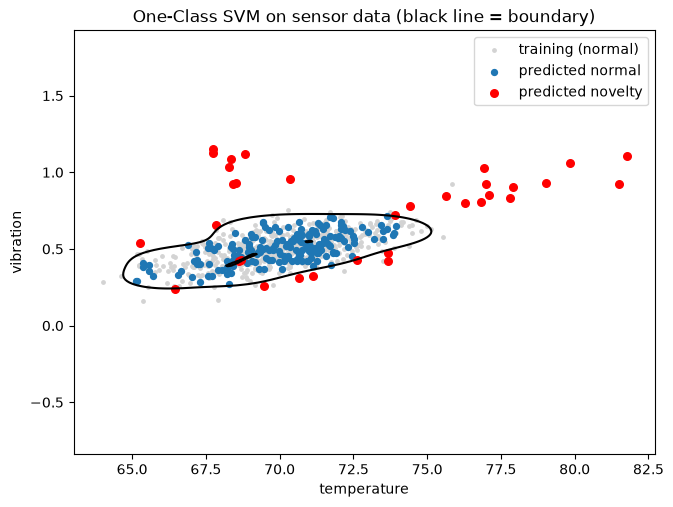

In [67]:
from sklearn.inspection import DecisionBoundaryDisplay

rng = np.random.default_rng(2024)
cov = [[4.0, 0.12], [0.12, 0.01]]                                                  # temperature and vibration are positively correlated
train_normal = rng.multivariate_normal([70, 0.5], cov, size=500)
test_normal = rng.multivariate_normal([70, 0.5], cov, size=200)
faults = np.r_[rng.multivariate_normal([78, 0.9], cov, size=12), rng.multivariate_normal([68, 1.1], cov, size=8)]   # overheating and a vibration fault
X_test3 = np.vstack([test_normal, faults]); y_test3 = np.r_[np.zeros(200), np.ones(20)]

oc3 = make_pipeline(StandardScaler(), OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)).fit(train_normal)
pred3 = (oc3.predict(X_test3) == -1).astype(int)
print(confusion_matrix(y_test3, pred3))
print(classification_report(y_test3, pred3, target_names=["normal", "fault"], digits=3))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
DecisionBoundaryDisplay.from_estimator(oc3, train_normal, response_method="decision_function", plot_method="contour", levels=[0], colors="k", ax=ax, grid_resolution=300, xlabel="temperature", ylabel="vibration")
ax.scatter(train_normal[:, 0], train_normal[:, 1], s=6, c="lightgray", label="training (normal)")
ax.scatter(X_test3[pred3 == 0, 0], X_test3[pred3 == 0, 1], s=18, c="tab:blue", label="predicted normal")
ax.scatter(X_test3[pred3 == 1, 0], X_test3[pred3 == 1, 1], s=30, c="red", label="predicted novelty")
ax.set_title("One-Class SVM on sensor data (black line = boundary)"); ax.legend(); plt.show()

The model accepts 187 of the 200 new normal readings (6.5% false alarms, a little above `nu = 0.05` because the test data differ from the training sample) and flags **all 20 faults** (recall 1.0); the fault precision is 0.61 (20 true faults among 33 alerts, since 13 normal readings are flagged too), giving F1 0.755. The boundary is a tilted ellipse that follows the temperature–vibration correlation, so readings that are plausible for each sensor separately but unusual *together* are caught. In a plant the choice of `nu` is a business decision: a smaller `nu` means fewer false alarms but a looser boundary that may miss faults.

## Chapter takeaways
1. **Outlier vs novelty:** outlier detection judges the training data themselves (`LOF` default, Isolation Forest's `fit_predict` style), novelty detection learns "normal" from clean data and scores *new* points (`OneClassSVM`, `LOF(novelty=True)`). `contamination` only sets a threshold — it fixed the number flagged (4/16/32/64 for 1/5/10/20%) whatever the data contain.
2. **Isolation Forest** isolates anomalies by few random splits; its score was recomputed by hand and `predict` is just `decision_function < 0`. Its axis-parallel splits give a cross-shaped boundary, it has no `feature_importances_`, and it is the weakest on local anomalies (AUC 0.74 vs LOF 0.99 on varying densities) but cost-predictable.
3. **One-Class SVM:** `nu` ≈ the share of training points treated as outliers — a *higher* `nu` gives a *tighter* boundary (the book states the opposite); `gamma` too large over-fits (30% of training data flagged); scaling is essential (65% vs 90% of novelties caught). The book's Figure 11.6 "failure" was a data bug (test inliers drawn around a different centre).
4. **LOF** compares local densities (recomputed by hand) and ranked a local outlier 16th vs Isolation Forest 39th and One-Class SVM 133rd; it *can* predict new data with `novelty=True`. Its weak spot is *k* smaller than a group of outliers (AUC 0.27 at *k* = 20 vs 0.998 at *k* = 50).
5. **Evaluation:** the book's ROC-AUC of **0.005** is a sign error — scikit-learn's scores are *higher = more normal*, so the score must be negated (AUC 0.995). Accuracy (98.2% vs 90.9% for "everything is normal") hides the real picture: look at precision/recall, average precision and the threshold trade-off.
6. **Handling:** removal, median replacement and capping each have side effects (duplicates at the median; capping altered 19 normal points); removal cannot live in a `Pipeline`; and when outliers come as a group, detect-and-remove helped little (MSE 3.7) while a robust `HuberRegressor` nearly matched the oracle (0.30 vs 0.25).
7. **Choosing:** measured, not asserted — Isolation Forest for large data and global anomalies, LOF for varying densities (and it is *fast*), One-Class SVM only for modest *n* with scaled data; `OneClassSVM` needs no labels either.

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| ROC-AUC in the evaluation recipe | prints 0.0051 and calls it the model's ability to distinguish classes | the score is inverted (`decision_function`: higher = more normal); negated it is **0.995** |
| One-Class SVM test data | "predictions are probably not the best … refine the hyperparameters" | a data bug: test "normal" points are centred at (0.3, 1.0), the training blob at (1.76, 3.98) — all 100 are flagged; no hyper-parameter fixes that |
| `nu` | "lower values create tighter margins"; higher flags fewer novelties | reversed: a higher `nu` flags *more* of the training/normal data (50% flagged at ν = 0.5) |
| Unseeded randomness | outliers drawn with `np.random.uniform` and no seed (Sections 3, 5, 6) | results depend on the earlier draws; `OneClassSVM.fit` itself consumes one global random number |
| One-Class SVM plot | red = *inliers*, blue = *novelties* | opposite to the colours of every other plot |
| LOF and `predict` | "strictly an unsupervised detector … not suitable for novelty detection" | true only for the default `novelty=False`; `LocalOutlierFactor(novelty=True)` predicts new data |
| Isolation Forest | "provides feature importance via `feature_importances_`" | no such attribute |
| Comparison table | "One-Class SVM learns from unlabeled data: No" | it needs no labels at all (only clean-ish data); "LOF scales: No" and "LOF high dimensions: No" not borne out up to 64,000 points (2-D) / 50-D with *k* ≥ group size |
| Winsorisation | caps 5th/95th percentiles as an outlier strategy | modifies 10% of every column incl. normal points (19 of 300 normal rows changed here) |
| Pipeline integration | "use `FunctionTransformer()` or `Pipeline` to encapsulate outlier handling" | removal drops rows from `X` but not `y` → `ValueError`; only row-preserving strategies fit |
| Handling recipe | computes `X_replaced` and `X_capped`, shows only removal | the other two are never inspected; replacement creates 30 duplicate points |
| Imports | `pd` missing from the evaluation recipe's imports | added |

*Chapters 1–11 are complete.*